In [ ]:
## Code for plotting RSA of sentence pair types based on the study design matrix
# Run with python 3.10 fMRI env
# James Fodor 2023

# load libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import json
import itertools

# load custom functions from library
sys.path.insert(0,'./..')
import voxels_processing as vp

# set display options
np.set_printoptions(precision=3, threshold=5000, linewidth=220, suppress=True, floatmode='fixed')
sns.set()

In [3]:
## Set stimuli and parameters for the relevant dataset

# select sentence dataset and specify if sentence pairs
dataset_name = 'Fodor2024-final108'
sims_path = 'Data-models/similarities/'

# load sentence set into dictionary depending on type
sentences_dict = vp.load_set_of_sentences('../'+dataset_name+'_sentences', pairs=False)
n = len(sentences_dict.keys()) # num sentences
print('Loaded',dataset_name,'with',n,'sentences')

# Load stimuli set
all_sentences = list(sentences_dict.values())
all_sentences_indices = np.arange(len(all_sentences))
sent_pairs_all = list(itertools.combinations(all_sentences_indices, 2))
sent_pair_ids_all = np.arange(len(sent_pairs_all))
num_stimuli = all_sentences_indices.shape[0]

# Print summary
print('Stimuli:',num_stimuli)
print('Pairs:',len(sent_pair_ids_all))

Loaded Fodor2024-final108 with 108 sentences
Stimuli: 108
Pairs: 5778


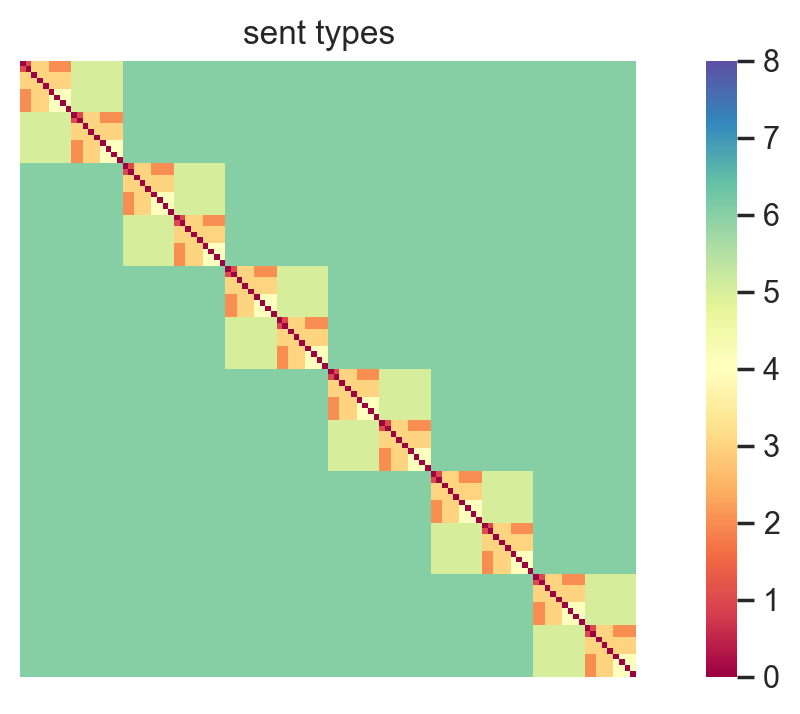

In [11]:
## Get type of sentence pairs based on design matrix

# load data
all_sentence_types = np.loadtxt('../Fodor2024-final108_types-detailed.txt', delimiter=';', dtype='str', encoding='utf-8')
        
# create empty storage array
sentpair_types_matrix = np.zeros([108,108],dtype=int)
sentpair_types_dict = {}

# loop over all pairs of sentences
for i,sent_type1 in enumerate(all_sentence_types):
    set1,subset1,type1,_ = sent_type1.split('.') # get type info for first sentence
    for j,sent_type2 in enumerate(all_sentence_types):
        set2,subset2,type2,_ = sent_type2.split('.') # get type info for second sentence
        
        # categorise the sentence pair
        if set1 != set2:
            pair_type = 6
        elif subset1 != subset2:
            pair_type = 5
        elif i==j:
            pair_type = 0
        elif (type1 == 'Base' and type2 == 'Same') or (type2 == 'Base' and type1 == 'Same'):
            pair_type = 1
        elif (type1 == 'Mod' and type2 in ['Base','Same']) or (type2 == 'Mod' and type1 in ['Base','Same']):
            pair_type = 2
        elif (type1 == 'Sub' and type2 in ['Mod','Base','Same']) or (type2 == 'Sub' and type1 in ['Mod','Base','Same']):
            pair_type = 3
        elif (type1 == 'Sub' and type2 == 'Sub'):
            pair_type = 3
        else:
            pair_type = 4

        # get final RSA matrix for plotting
        sentpair_types_matrix[i,j] = pair_type # store pair type
        if (i,j) in sent_pairs_all:
            sentpair_types_dict[sent_pairs_all.index((i,j))] = pair_type # store in dictionary mapping pair ID to pair type

# save results to file
sentpair_types_list = list(sentpair_types_dict.values())
np.savetxt('../Fodor2024-final108_types-brief.txt', sentpair_types_list, fmt='%d')

# plot types RSA
fig = plt.figure(figsize=(9,4), dpi=200)
vp.add_heatmap_subplot(fig, (1,1,1), sentpair_types_matrix, 'sent types', sbj_id='', subplot='', colorbar=True, cmap='Spectral', min=0, max=8)
plt.savefig('../Figures/sent_types_RSA.png', bbox_inches='tight')
plt.show()

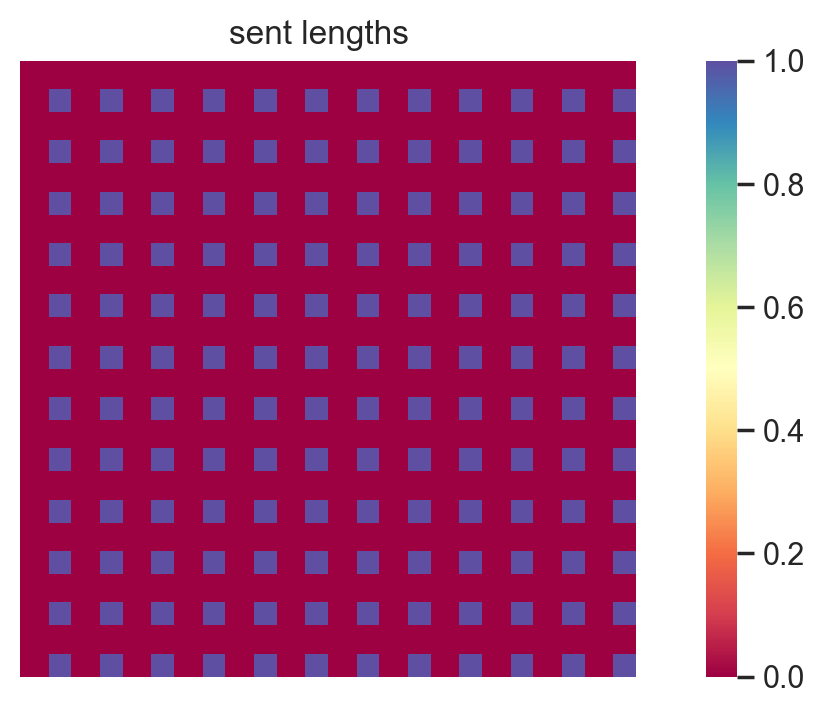

In [13]:
## Get length of sentence pairs based on minlength

# create empty storage array
sentpair_types_matrix = np.zeros([108,108],dtype=int)
sentpair_types_dict = {}

# loop over all pairs of sentences
for i,sent_type1 in enumerate(all_sentence_types):
    set1,subset1,type1,_ = sent_type1.split('.') # get type info for first sentence
    for j,sent_type2 in enumerate(all_sentence_types):
        set2,subset2,type2,_ = sent_type2.split('.') # get type info for second sentence
        
        # categorise the sentence pair
        if (type1 == 'Mod' and type2 =='Mod'):
            pair_type = 1
        else:
            pair_type = 0

        # get final RSA matrix for plotting
        sentpair_types_matrix[i,j] = pair_type # store pair type
        if (i,j) in sent_pairs_all:
            sentpair_types_dict[sent_pairs_all.index((i,j))] = pair_type # store in dictionary mapping pair ID to pair type

# save results to file
sentpair_types_list = list(sentpair_types_dict.values())
np.savetxt('../Fodor2024-final108_long_pairs.txt', sentpair_types_list, fmt='%d')

# plot types RSA
fig = plt.figure(figsize=(9,4), dpi=200)
vp.add_heatmap_subplot(fig, (1,1,1), sentpair_types_matrix, 'sent lengths', sbj_id='', subplot='', colorbar=True, cmap='Spectral', min=0, max=1)
plt.savefig('../Figures/sent_lengths_RSA.png', bbox_inches='tight')
plt.show()